In [127]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
print("VS Code setup complete!")
print("Python interpreter:", sys.executable)
print("NumPy version:", np.__version__)
print("pandas version:", pd.__version__)
import numpy as np
from sklearn.model_selection import train_test_split
import scipy.optimize as opt


VS Code setup complete!
Python interpreter: c:\Users\billy\AppData\Local\Python\pythoncore-3.14-64\python.exe
NumPy version: 2.5.3
pandas version: 3.0.6


In [128]:
#1
# Reused from my Project 2 notebook
# Read and summarize the raw data
df_raw = pd.read_csv("ims_setup_project02.csv")

display(df_raw.head())
print("Rows:", df_raw.shape[0], " Columns:", df_raw.shape[1])
print("Missing values per column:")
print(df_raw.isna().sum())

# Project 2 cleaning steps
df = df_raw[["lap", "rear_wing_angle_deg", "rear_ride_height_mm",
             "sector_3_time_s", "top_speed_kph"]].copy()

df["lap"] = pd.to_numeric(df["lap"], errors="coerce")
df["rear_wing_angle_deg"] = pd.to_numeric(df["rear_wing_angle_deg"], errors="coerce")
df["rear_ride_height_mm"] = pd.to_numeric(df["rear_ride_height_mm"], errors="coerce")
df["sector_3_time_s"] = pd.to_numeric(df["sector_3_time_s"], errors="coerce")
df["top_speed_kph"] = pd.to_numeric(df["top_speed_kph"], errors="coerce")

df = df.drop_duplicates()
df = df.dropna()
print("Rows after cleaning:", len(df))

# Setup-level DataFrame
df_grouped = (
    df.groupby(["rear_wing_angle_deg", "rear_ride_height_mm"], as_index=False)
      .agg(
          mean_sector_3_time_s=("sector_3_time_s", "mean"),
          std_sector_3_time_s=("sector_3_time_s", "std"),
          valid_laps=("sector_3_time_s", "count")
      )
)

display(df_grouped)
print("Number of unique setups:", len(df_grouped))
df_grouped.to_csv(f"wfrazer_pr03_grouped.csv", index=False)

,lap,rear_wing_angle_deg,rear_ride_height_mm,sector_3_time_s,top_speed_kph
0,1,5,35,33.0949,286.761
1,2,5,35,32.9325,287.079
2,3,5,35,33.0858,287.261
3,4,5,35,33.0472,287.059
4,5,5,35,33.0534,287.463


Rows: 135  Columns: 5
Missing values per column:
lap                    0
rear_wing_angle_deg    0
rear_ride_height_mm    0
sector_3_time_s        0
top_speed_kph          0
dtype: int64
Rows after cleaning: 135


,rear_wing_angle_deg,rear_ride_height_mm,mean_sector_3_time_s,std_sector_3_time_s,valid_laps
0,5,35,33.04276,0.064925,5
1,5,40,32.85104,0.104126,5
2,5,45,32.99286,0.022043,5
3,6,35,32.51308,0.053101,5
4,6,40,32.38096,0.050323,5
5,6,45,32.44690,0.077138,5
6,7,35,32.03248,0.035651,5
7,7,40,31.86244,0.059775,5
8,7,45,32.01484,0.053106,5
9,8,35,31.68490,0.054910,5


Number of unique setups: 27


In [129]:
#2
# Sort by the two inputs and reset the index
df_grouped = df_grouped.sort_values(["rear_wing_angle_deg", "rear_ride_height_mm"]).reset_index(drop=True)

# Unique setup ID: 1 to 27
df_grouped["setup_id"] = np.arange(1, len(df_grouped) + 1)

# Split the 27 unique setups
df_train, df_test = train_test_split(df_grouped, test_size=0.25, random_state=42)

print("Training setups:", len(df_train))
print("Test setups:", len(df_test))
print("setup_id in df_train:", "setup_id" in df_train.columns)

Training setups: 20
Test setups: 7
setup_id in df_train: True


Why the repeated laps must stay together, as each group of 5 laps are one configuration each, there do not want the test to see any of the training data.

In [130]:
#3
# Create X_train and X_test with input columns: rear_wing_angle_deg and rear_ride_height_mm
X_train = df_train[["rear_wing_angle_deg", "rear_ride_height_mm"]].to_numpy(dtype=float)
X_test = df_test[["rear_wing_angle_deg", "rear_ride_height_mm"]].to_numpy(dtype=float)

# 1D y_train and y_test, responses. mean Sector 3 time, (1d as only 1 output)
y_train = df_train["mean_sector_3_time_s"].to_numpy()
y_test = df_test["mean_sector_3_time_s"].to_numpy()

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (20, 2)
X_test shape: (7, 2)
y_train shape: (20,)
y_test shape: (7,)


In [131]:
#4
# Fixed design bounds from Project 2: 5-13 deg wing, 35-45 mm ride height
lower = np.array([5.0, 35.0])
upper = np.array([13.0, 45.0])

# Verifying
data_min = df_grouped[["rear_wing_angle_deg", "rear_ride_height_mm"]].min().to_numpy()
data_max = df_grouped[["rear_wing_angle_deg", "rear_ride_height_mm"]].max().to_numpy()
print("Prescribed bounds:", lower, upper)
print("Dataset min/max:  ", data_min, data_max)
print("Bounds match dataset:", np.allclose(lower, data_min) and np.allclose(upper, data_max))

# Normalize inputs to [0, 1] using the fixed bounds Zj
def normalize(X):
    return (X - lower) / (upper - lower)

Z_train = normalize(X_train)
Z_test = normalize(X_test)

print("Z_train range:", Z_train.min(axis=0), "to", Z_train.max(axis=0))
print("Z_test range:", Z_test.min(axis=0), "to", Z_test.max(axis=0))

Prescribed bounds: [ 5. 35.] [13. 45.]
Dataset min/max:   [ 5 35] [13 45]
Bounds match dataset: True
Z_train range: [0. 0.] to [1. 1.]
Z_test range: [0. 0.] to [0.875 1.   ]


In [132]:
#5
# Gaussian kernel and Gram matrix adapted from Lec 13

# Gaussian RBF , 2-D version: squared distance from every row of X to one center c
def phi(X, c, sigma):
    num = np.sum((X - c)**2, axis=1) 
    den = 2 * sigma**2
    return np.exp(-num / den)

# Kernel matrix: one column per center
def rbf_matrix(A, B, sigma):
    return np.column_stack([phi(A, c, sigma) for c in B])

Phi_gram = rbf_matrix(Z_train, Z_train, sigma=0.20)
print("Training Gram matrix shape:", Phi_gram.shape)
print("Diagonal entries all equal 1:", np.allclose(np.diag(Phi_gram), 1.0))

Training Gram matrix shape: (20, 20)
Diagonal entries all equal 1: True


In [133]:
#6
# Fit weights: (Phi + lam*I) b = y 
def fit_rbf(X, y, sigma, lam):
    centers = X.copy()
    Phi_gram = rbf_matrix(X, centers, sigma)
    b = np.linalg.solve(Phi_gram + lam * np.eye(len(X)), y)
    return b

# Predict: evaluate the same basis functions at new points
def predict_rbf(X_new, centers, b, sigma):
    Phi_eval = rbf_matrix(X_new, centers, sigma)
    return Phi_eval @ b

In [134]:
#7
from scipy.interpolate import RBFInterpolator

sigma_check = 0.20
lam_check = 0.01

# My RBF
b_check = fit_rbf(Z_train, y_train, sigma_check, lam_check)

# SciPy RBF with the same settings
rbf_scipy = RBFInterpolator(Z_train, y_train, kernel="gaussian",
                            epsilon=1/(np.sqrt(2)*sigma_check),
                            smoothing=lam_check, degree=-1)

# Five extra points inside the normalized domain
Z_extra = np.array([[0.10, 0.20],
                    [0.35, 0.75],
                    [0.50, 0.50],
                    [0.70, 0.30],
                    [0.90, 0.90]])

diff_train = np.max(np.abs(predict_rbf(Z_train, Z_train, b_check, sigma_check) - rbf_scipy(Z_train)))
diff_extra = np.max(np.abs(predict_rbf(Z_extra, Z_train, b_check, sigma_check) - rbf_scipy(Z_extra)))

print("Max difference at training inputs:", diff_train)
print("Max difference at extra points:", diff_extra)

Max difference at training inputs: 2.1316282072803006e-14
Max difference at extra points: 1.0658141036401503e-14


In [135]:
#8
sigma_default = 0.20
lam_default = 0.01

b_default = fit_rbf(Z_train, y_train, sigma_default, lam_default)
yhat_train_default = predict_rbf(Z_train, Z_train, b_default, sigma_default)

rmse_train_default = np.sqrt(np.mean((y_train - yhat_train_default)**2))
print("Default RBF training RMSE (s):", rmse_train_default)

Default RBF training RMSE (s): 0.25336241965548606


**SciPy equivalence check.** Using the same training data, sigma = 0.20 and lambda = 0.01, my RBF matches scipy.interpolate.RBFInterpolator to about 1e-14 s at both the training inputs and five extra points in the domain. Nothing to invesitgate.

**Fitted parameters and hyperparameters.** The weights b are the fitted parameters. They are calculated from the training data by solving the equation from item 6, (Phi + lambda*I) b = y, giving one weight per center.

The kernel width sigma and the regularization lambda are hyperparameters. They are chosen before fitting and control the shape and smoothness of the model. The centers are also fixed in advance as the training setups.

**Default model.** With sigma = 0.20 and lambda = 0.01, the default RBF has a training RMSE of about 0.253 s.

In [ ]:
#9
# LOOCV loop adapted from Lec 15
def loocv_rbf(X, y, sigma, lam):
    n = len(y)
    y_pred = np.zeros(n)

    for i in range(n):
        # Remove setup i from both the fitting data and the centers
        keep = np.arange(n) != i
        X_fit = X[keep]
        y_fit = y[keep]

        # Refit the weights for this fold
        b_fold = fit_rbf(X_fit, y_fit, sigma, lam)

        # Predict the omitted setup the remaining centers
        y_pred[i] = predict_rbf(X[i:i+1], X_fit, b_fold, sigma)[0]

    return y_pred

In [137]:
#10
y_loo_default = loocv_rbf(Z_train, y_train, sigma_default, lam_default)

e_default = y_train - y_loo_default
PRESS_default = np.sum(e_default**2)
RMSE_CV_default = np.sqrt(PRESS_default / len(y_train))

print("Default PRESS (s^2):", PRESS_default)
print("Default RMSE_CV (s):", RMSE_CV_default)
print("Default training RMSE (s):", rmse_train_default)

Default PRESS (s^2): 606.2052237305058
Default RMSE_CV (s): 5.505475564065769
Default training RMSE (s): 0.25336241965548606


In [138]:
#11 12
sigma_values = np.logspace(-1.3, 0, 15)
lam_values = np.logspace(-8, 0, 9)

rows = []
for sigma in sigma_values:
    for lam in lam_values:
        try:
            y_loo = loocv_rbf(Z_train, y_train, sigma, lam)
            PRESS = np.sum((y_train - y_loo)**2)
            if not np.isfinite(PRESS):
                raise ValueError("nonfinite PRESS")
            rows.append([sigma, lam, PRESS, np.sqrt(PRESS / len(y_train)), "ok"])
        except (np.linalg.LinAlgError, ValueError):
            rows.append([sigma, lam, np.inf, np.inf, "failed"])

df_cv_search = pd.DataFrame(rows, columns=["sigma", "lam", "PRESS", "RMSE_CV", "status"])
print("Pairs evaluated:", len(df_cv_search))
print(df_cv_search["status"].value_counts())

Pairs evaluated: 135
status
ok    135
Name: count, dtype: int64


In [139]:
#13
# Lowest RMSE_CV; ties broken by larger lam and then smaller sigma
df_ok = df_cv_search[df_cv_search["status"] == "ok"]
df_ranked = df_ok.sort_values(["RMSE_CV", "lam", "sigma"], ascending=[True, False, True])

display(df_ranked.head(5))

sigma_best = df_ranked.iloc[0]["sigma"]
lam_best = df_ranked.iloc[0]["lam"]
RMSE_CV_best = df_ranked.iloc[0]["RMSE_CV"]

reduction = (RMSE_CV_default - RMSE_CV_best) / RMSE_CV_default * 100
print("Selected sigma:", sigma_best)
print("Selected lam:", lam_best)
print("Selected RMSE_CV (s):", RMSE_CV_best)
print("Reduction in RMSE_CV vs default (%):", reduction)

,sigma,lam,PRESS,RMSE_CV,status
108,0.652057,1.000000e-08,0.126111,0.079407,ok
117,0.807501,1.000000e-08,0.150051,0.086617,ok
109,0.652057,1.000000e-07,0.154902,0.088006,ok
129,1.000000,1.000000e-05,0.162077,0.090021,ok
99,0.526537,1.000000e-08,0.171398,0.092574,ok


Selected sigma: 0.6520572293428615
Selected lam: 1e-08
Selected RMSE_CV (s): 0.07940735958137161
Reduction in RMSE_CV vs default (%): 98.55766575189865


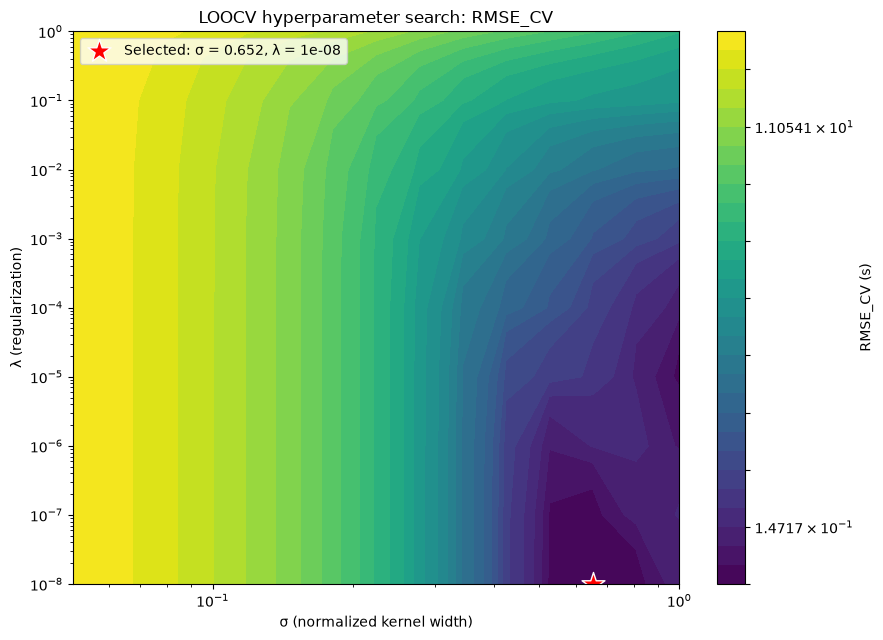

In [140]:
#14
from matplotlib.colors import LogNorm

# Reshape into a grid, rows=sigma, columns=lam
RMSE_grid = df_cv_search["RMSE_CV"].to_numpy().reshape(len(sigma_values), len(lam_values))
RMSE_grid = np.ma.masked_invalid(RMSE_grid)     # mask failed pairs (inf)

S, L = np.meshgrid(sigma_values, lam_values, indexing="ij")
levels = np.logspace(np.log10(RMSE_grid.min()), np.log10(RMSE_grid.max()), 30)

plt.figure(figsize=(9, 6.5))
cf = plt.contourf(S, L, RMSE_grid, levels=levels, norm=LogNorm(), cmap="viridis")
plt.colorbar(cf, label="RMSE_CV (s)")
plt.scatter(sigma_best, lam_best, marker="*", s=300, c="red", edgecolor="white",
            label=f"Selected: σ = {sigma_best:.3f}, λ = {lam_best:.0e}")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("σ (normalized kernel width)")
plt.ylabel("λ (regularization)")
plt.title("LOOCV hyperparameter search: RMSE_CV")
plt.legend(loc="upper left")
plt.tight_layout()
plt.savefig("wfrazer_pr03_cv_search.png", dpi=200)
plt.show()

In [141]:
#15
y_loo_best = loocv_rbf(Z_train, y_train, sigma_best, lam_best)

# Setup ID lookup: sorted by wing angle then ride height, numbered 1-27
lookup = df_grouped[["rear_wing_angle_deg", "rear_ride_height_mm"]].drop_duplicates()
lookup = lookup.sort_values(["rear_wing_angle_deg", "rear_ride_height_mm"]).reset_index(drop=True)
lookup["setup_id"] = np.arange(1, len(lookup) + 1)

# Match each training setup to its ID
train_ids = df_train[["rear_wing_angle_deg", "rear_ride_height_mm"]].merge(
    lookup, on=["rear_wing_angle_deg", "rear_ride_height_mm"], how="left")["setup_id"].values

df_loo = pd.DataFrame({
    "setup_id": train_ids,
    "rear_wing_angle_deg": df_train["rear_wing_angle_deg"].values,
    "rear_ride_height_mm": df_train["rear_ride_height_mm"].values,
    "actual_time_s": y_train,
    "predicted_time_s": y_loo_best,
    "residual_s": y_train - y_loo_best
}).sort_values("setup_id")
display(df_loo)

abs_res = df_loo["residual_s"].abs()
print("Largest |residual|:")
display(df_loo.loc[[abs_res.idxmax()]])
print("Smallest |residual|:")
display(df_loo.loc[[abs_res.idxmin()]])

,setup_id,rear_wing_angle_deg,rear_ride_height_mm,actual_time_s,predicted_time_s,residual_s
3,2,5,40,32.85104,33.030382,-0.179342
6,3,5,45,32.99286,33.047647,-0.054787
9,4,6,35,32.51308,32.576898,-0.063818
4,5,6,40,32.38096,32.336081,0.044879
5,6,6,45,32.44690,32.410609,0.036291
19,7,7,35,32.03248,32.004831,0.027649
15,8,7,40,31.86244,31.890428,-0.027988
16,11,8,40,31.55450,31.512528,0.041972
1,13,9,35,31.44076,31.452658,-0.011898
17,15,9,45,31.54258,31.552755,-0.010175


Largest |residual|:


,setup_id,rear_wing_angle_deg,rear_ride_height_mm,actual_time_s,predicted_time_s,residual_s
2,25,13,35,31.59024,31.366482,0.223758


Smallest |residual|:


,setup_id,rear_wing_angle_deg,rear_ride_height_mm,actual_time_s,predicted_time_s,residual_s
0,18,10,45,31.44488,31.440167,0.004713


In [142]:
#16
def quad_design(Z):
    z1 = Z[:, 0]
    z2 = Z[:, 1]
    return np.column_stack([np.ones(len(Z)), z1, z2, z1**2, z2**2, z1*z2])

def fit_quad(Z, y):
    return np.linalg.pinv(quad_design(Z)) @ y

def predict_quad(Z_new, b):
    return quad_design(Z_new) @ b

def loocv_quad(Z, y):
    n = len(y)
    y_pred = np.zeros(n)
    for i in range(n):
        keep = np.arange(n) != i
        b_fold = fit_quad(Z[keep], y[keep])            # refit in every fold
        y_pred[i] = predict_quad(Z[i:i+1], b_fold)[0]
    return y_pred

y_loo_quad = loocv_quad(Z_train, y_train)
RMSE_CV_quad = np.sqrt(np.mean((y_train - y_loo_quad)**2))
print("Quadratic RMSE_CV (s):", RMSE_CV_quad)

Quadratic RMSE_CV (s): 0.026529428268887358


In [143]:
#17
df_cv_compare = pd.DataFrame({
    "model": ["Default RBF", "Tuned RBF", "Quadratic"],
    "RMSE_CV_s": [RMSE_CV_default, RMSE_CV_best, RMSE_CV_quad]
})
display(df_cv_compare)
print("Lowest RMSE_CV:", df_cv_compare.loc[df_cv_compare["RMSE_CV_s"].idxmin(), "model"])

# Freeze the selected RBF hyperparameters before looking at the test set
sigma_final = sigma_best
lam_final = lam_best
print("Frozen sigma:", sigma_final, " Frozen lam:", lam_final)

,model,RMSE_CV_s
0,Default RBF,5.505476
1,Tuned RBF,0.079407
2,Quadratic,0.026529


Lowest RMSE_CV: Quadratic
Frozen sigma: 0.6520572293428615  Frozen lam: 1e-08


before using the test set.
The quadratic model has the lowest RMSE_CV,  

The tuned RBF hyperparameters sigma 0.652$, lambda = 10^-8were frozen at this point and were not revised after seeing the test results.

In [144]:
#18
def rmse(y, yhat):
    return np.sqrt(np.mean((y - yhat)**2))

def mae(y, yhat):
    return np.mean(np.abs(y - yhat))

def r2(y, yhat):
    # Coefficient of determination using test-set values only (no clipping)
    return 1 - np.sum((y - yhat)**2) / np.sum((y - np.mean(y))**2)

# Default RBF
b_def = fit_rbf(Z_train, y_train, sigma_default, lam_default)
train_def = predict_rbf(Z_train, Z_train, b_def, sigma_default)
test_def = predict_rbf(Z_test, Z_train, b_def, sigma_default)

# Tuned RBF
b_tun = fit_rbf(Z_train, y_train, sigma_final, lam_final)
train_tun = predict_rbf(Z_train, Z_train, b_tun, sigma_final)
test_tun = predict_rbf(Z_test, Z_train, b_tun, sigma_final)

# Quadratic
b_quad = fit_quad(Z_train, y_train)
train_quad = predict_quad(Z_train, b_quad)
test_quad = predict_quad(Z_test, b_quad)

df_validation = pd.DataFrame({
    "model": ["Default RBF", "Tuned RBF", "Quadratic"],
    "sigma": [sigma_default, sigma_final, np.nan],
    "lam": [lam_default, lam_final, np.nan],
    "train_RMSE_s": [rmse(y_train, train_def), rmse(y_train, train_tun), rmse(y_train, train_quad)],
    "RMSE_CV_s": [RMSE_CV_default, RMSE_CV_best, RMSE_CV_quad],
    "test_RMSE_s": [rmse(y_test, test_def), rmse(y_test, test_tun), rmse(y_test, test_quad)],
    "test_MAE_s": [mae(y_test, test_def), mae(y_test, test_tun), mae(y_test, test_quad)],
    "test_R2": [r2(y_test, test_def), r2(y_test, test_tun), r2(y_test, test_quad)]
})
display(df_validation)
df_validation.to_csv("wfrazer_pr03_validation.csv", index=False)

,model,sigma,lam,train_RMSE_s,RMSE_CV_s,test_RMSE_s,test_MAE_s,test_R2
0,Default RBF,0.200000,1.000000e-02,0.253362,5.505476,3.169248,2.231456,-29.154571
1,Tuned RBF,0.652057,1.000000e-08,0.000774,0.079407,0.121868,0.086699,0.955412
2,Quadratic,NaN,NaN,0.019241,0.026529,0.025850,0.018986,0.997994


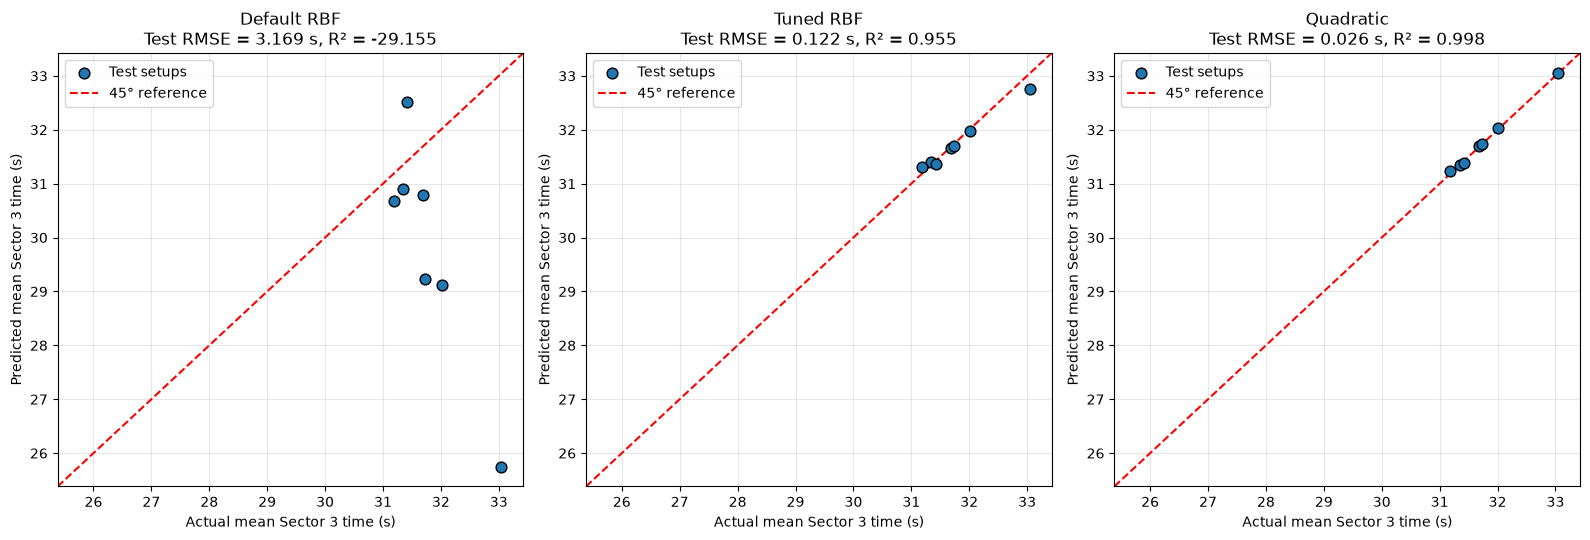

In [145]:
#19
preds = [test_def, test_tun, test_quad]
names = ["Default RBF", "Tuned RBF", "Quadratic"]

# Consistent limits across all three panels
all_vals = np.concatenate([y_test] + preds)
pad = 0.05 * (all_vals.max() - all_vals.min())
lims = [all_vals.min() - pad, all_vals.max() + pad]

fig, ax = plt.subplots(1, 3, figsize=(16, 5.5))
for k in range(3):
    ax[k].scatter(y_test, preds[k], edgecolor="k", s=60, zorder=3, label="Test setups")
    ax[k].plot(lims, lims, "r--", label="45° reference")
    ax[k].set_xlim(lims)
    ax[k].set_ylim(lims)
    ax[k].set_xlabel("Actual mean Sector 3 time (s)")
    ax[k].set_ylabel("Predicted mean Sector 3 time (s)")
    ax[k].set_title(f"{names[k]}\nTest RMSE = {rmse(y_test, preds[k]):.3f} s, R² = {r2(y_test, preds[k]):.3f}")
    ax[k].grid(alpha=0.3)
    ax[k].legend(loc="upper left")

plt.tight_layout()
plt.savefig("wfrazer_pr03_test_comparison.png", dpi=200)
plt.show()

Tuning improved the RBF dramatically. RMSE_CV fell from about 5.5 s to 0.079 s, and test RMSE fell from about 3.17 s to 0.122 s. 

The default model's test R^2of about -29 means it predicts the test setups far worse than simply using their mean, because its narrow Gaussians and lack of an intercept let predictions collapse below the ~31 s baseline between training setups.

The quadratic reference model is best of the three on every out-of-sample measure. This suggests the true Sector 3 response over this region is smooth and close to quadratic, so a six-parameter global model captures it efficiently.

The cross-validation ranking quadratic, then tuned RBF, then default RBF agrees with the test ranking. 

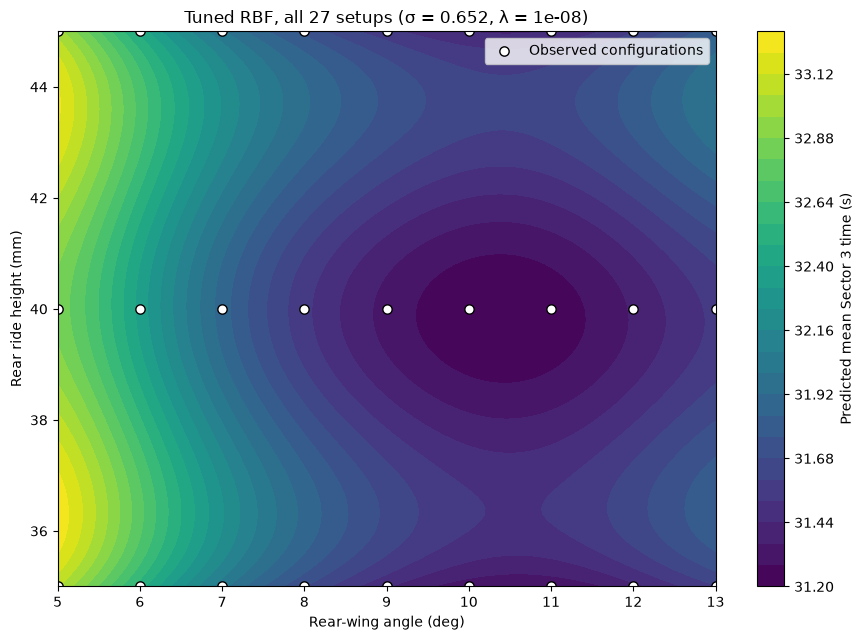

Predicted range (s): 31.209816811868222 to 33.25665250708698


In [146]:
#21
# Refit the tuned RBF on all configurations
X_all = df_grouped[["rear_wing_angle_deg", "rear_ride_height_mm"]].to_numpy(dtype=float)
y_all = df_grouped["mean_sector_3_time_s"].to_numpy()
Z_all = normalize(X_all)

b_all = fit_rbf(Z_all, y_all, sigma_final, lam_final)

#Physical coordiantes
x1_grid = np.linspace(lower[0], upper[0], 101)
x2_grid = np.linspace(lower[1], upper[1], 101)
X1, X2 = np.meshgrid(x1_grid, x2_grid)

# Normalized
grid_points = np.column_stack([X1.ravel(), X2.ravel()])
Z_grid = normalize(grid_points)
T_grid_all = predict_rbf(Z_grid, Z_all, b_all, sigma_final).reshape(X1.shape)

plt.figure(figsize=(9, 6.5))
cf = plt.contourf(X1, X2, T_grid_all, levels=30, cmap="viridis")
plt.colorbar(cf, label="Predicted mean Sector 3 time (s)")
plt.scatter(X_all[:, 0], X_all[:, 1], c="white", edgecolor="k", s=45, label="Observed configurations")
plt.xlabel("Rear-wing angle (deg)")
plt.ylabel("Rear ride height (mm)")
plt.title(f"Tuned RBF, all 27 setups (σ = {sigma_final:.3f}, λ = {lam_final:.0e})")
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig("wfrazer_pr03_rbf_surface.png", dpi=200)
plt.show()

print("Predicted range (s):", T_grid_all.min(), "to", T_grid_all.max())

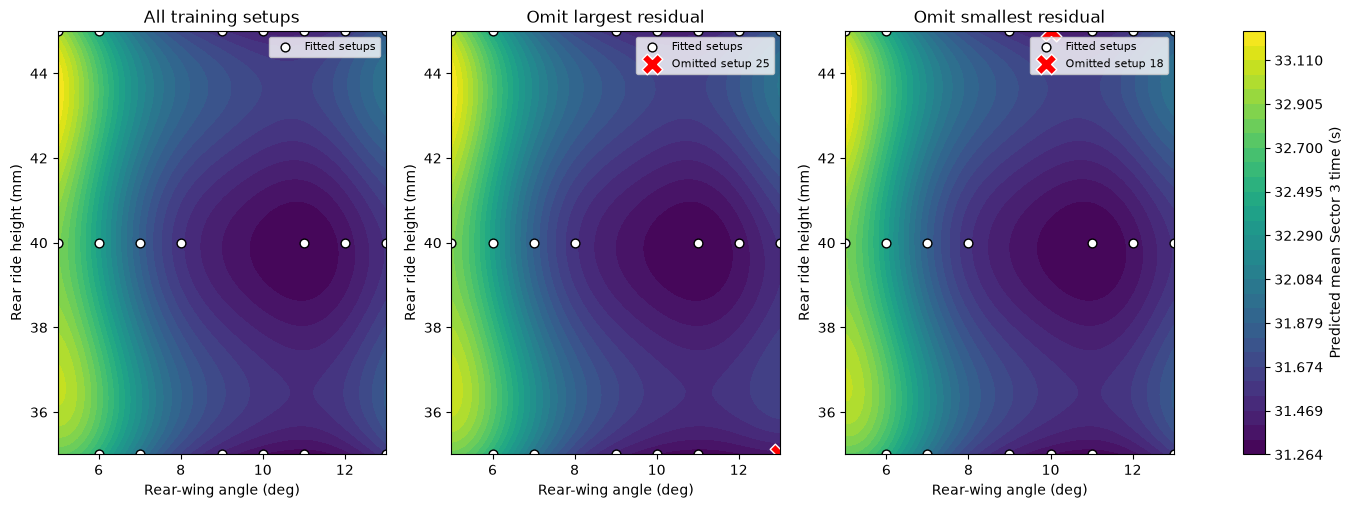

Omit largest residual | max change (s): 0.2237366561239469 | mean change (s): 0.005913727798305842
Omit smallest residual | max change (s): 0.010151494378078496 | mean change (s): 0.0011711207317904374


In [147]:
#22
# Setups with the largest and smallest residuals
row_big = df_loo.loc[df_loo["residual_s"].abs().idxmax()]
row_small = df_loo.loc[df_loo["residual_s"].abs().idxmin()]

def omit_setup(wing, ride):
    keep = ~((X_train[:, 0] == wing) & (X_train[:, 1] == ride))
    return Z_train[keep], y_train[keep], X_train[keep]

cases = [
    ("All training setups", Z_train, y_train, X_train, None),
    ("Omit largest residual", *omit_setup(row_big["rear_wing_angle_deg"], row_big["rear_ride_height_mm"]), row_big),
    ("Omit smallest residual", *omit_setup(row_small["rear_wing_angle_deg"], row_small["rear_ride_height_mm"]), row_small),
]

# Refit each model and predict on the same grid
surfaces = []
for name, Zc, yc, Xc, omitted in cases:
    b_c = fit_rbf(Zc, yc, sigma_final, lam_final)
    surfaces.append(predict_rbf(Z_grid, Zc, b_c, sigma_final).reshape(X1.shape))

# Shared colour limits
levels = np.linspace(min(s.min() for s in surfaces), max(s.max() for s in surfaces), 30)

fig, ax = plt.subplots(1, 3, figsize=(18, 5.5))
for k, (name, Zc, yc, Xc, omitted) in enumerate(cases):
    cf = ax[k].contourf(X1, X2, surfaces[k], levels=levels, cmap="viridis")
    ax[k].scatter(Xc[:, 0], Xc[:, 1], c="white", edgecolor="k", s=40, label="Fitted setups")
    if omitted is not None:
        ax[k].scatter(omitted["rear_wing_angle_deg"], omitted["rear_ride_height_mm"], marker="X", s=220,
                      c="red", edgecolor="white", label=f"Omitted setup {int(omitted['setup_id'])}")
    ax[k].set_xlabel("Rear-wing angle (deg)")
    ax[k].set_ylabel("Rear ride height (mm)")
    ax[k].set_title(name)
    ax[k].legend(loc="upper right", fontsize=8)

fig.colorbar(cf, ax=ax, label="Predicted mean Sector 3 time (s)")
plt.savefig("wfrazer_pr03_omitted_surfaces.png", dpi=200, bbox_inches="tight")
plt.show()

# How much each  changes the surface
for k in [1, 2]:
    d = np.abs(surfaces[k] - surfaces[0])
    print(cases[k][0], "| max change (s):", d.max(), "| mean change (s):", d.mean())

#23

Discussion on model behavior

How sigma and lambda affect the model- sigma sets how far each Gaussian reaches in normalized space. A small sigma gives narrow, isolated bumps. 

A larger sigma makes neighboring bumps overlap, so together they can carry the ~31 s baseline smoothly across the domain. lambda controls regularization. With lambda near zero the model interpolates its training data, noise included; larger lambda shrinks the weights and smooths the fit, but too much pulls predictions toward zero, as the default model showed.

Why training RMSE can't select them- Because each training setup has its own center, training error can be made almost zero by shrinking sigma or lambda.

 The tuned RBF's training RMSE was about 0.001 s, while its RMSE_CV was     0.079 s. Only error at setups the model has not seen, as measured by LOOCV, rewards good prediction.

What the error contour shows- Only a small region of the search gives low error: wide kernels approx about 0.5, with small lambda. Smaller sigma$values give errors of several seconds, so the model is very sensitive to the kernel width. The best pair uses lambda = 10^-8, the smallest value tested, so it sits on the edge of the search. 

That means I can't be sure it's the true optimum or if an even smaller lambda might be better. Overall, the data favor wide, overlapping Gaussians that pass almost exactly through the training setups.

*hat changes when observations are omitted- Removing setup 25 (13°, 35 mm), the largest LOOCV residual, changes the surface by up to about 0.22 s, but only near that corner, where the model loses its only nearby support and must extrapolate. Its average change across the grid is about 0.006 s. 

Removing setup 18 (10°, 45 mm), the smallest residual, changes the surface by at most about 0.01 s, because neighboring setups already constrain that region. A large omitted-point error therefore reflects local sensitivity at a poorly supported location, not instability of the whole surface.

#24 Recommendation: 
I recommend the quadratic model for predicting Sector 3 time. 

It had the lowest RMSE_CV, and the held-out test setups agreed.

It also uses 6 parameters instead of 20 weights plus two tuned hyperparameters, so it is simpler and less sensitive to individual setups.

Limitations.
- Sparse coverage only 27 setups on a 9 × 3 grid, with just three ride-height levels, so curvature in ride height is weakly defined and corners rely on extrapolation.

- Noisy setup means: each mean comes from 5 laps with a within-setup scatter of about 0.06 s, larger than the quadratic's prediction error, so the models are near the limit of what the data can resolve.
- Search bounds: the RBF's selected lambda lies on the edge of the grid.

- Numerical conditioning with sigma approx 0.65 and lambda = 10^-8 the RBF Gram matrix has a condition number around 10^9, so its weights are sensitive to small changes in the data.

The all-data RBF refit in item 21 uses every setup, including the former test set, so no independent test data remain* to check it; its accuracy can only be inferred from the earlier validation. 

Its surface also does not verify a physical optimum: it is a fitted prediction of mean Sector 3 time only, it says nothing about the Project 2 top-speed constraint of 284 kph, and any setup it suggests would still need track running or simulation to confirm.

In [148]:
#25
from sklearn.neural_network import MLPRegressor
import warnings

df_lap = pd.read_csv("simulated_laptime_data.csv")

display(df_lap.head())
display(df_lap.describe())
print("Rows:", len(df_lap))
print("Missing values per column:")
print(df_lap.isna().sum())

# Keep the original zero-based row index as row_id
df_lap["row_id"] = df_lap.index

,fuel_kg,tire_age_laps,time_s
0,22.189146,7.846392,64.810266
1,29.207419,5.174721,65.917722
2,16.306554,10.407846,65.457985
3,29.178391,7.585621,65.778464
4,18.989303,9.723292,65.446376


,fuel_kg,tire_age_laps,time_s
count,100.000000,100.000000,100.000000
mean,22.209104,6.037854,65.101500
std,4.615793,3.263998,0.964395
min,14.093194,0.200674,63.108675
25%,18.199190,3.511454,64.372019
50%,22.223122,5.598018,65.020940
75%,26.468585,9.008879,65.619956
max,29.691795,11.988311,67.987389


Rows: 100
Missing values per column:
fuel_kg          0
tire_age_laps    0
time_s           0
dtype: int64


In [149]:
#26
# Adapted from Lec 16
df_lap["row_id"] = df_lap.index
df_lap_train, df_lap_test = train_test_split(df_lap, test_size=0.25, random_state=42)

# Features and target
X_nn_train = df_lap_train[["fuel_kg", "tire_age_laps"]]
X_nn_test = df_lap_test[["fuel_kg", "tire_age_laps"]]
y_nn_train = df_lap_train["time_s"].to_numpy()
y_nn_test = df_lap_test["time_s"].to_numpy()

# Normalization using TRAINING data only
X_nn_min = X_nn_train.min().to_numpy()
X_nn_max = X_nn_train.max().to_numpy()
print("Training min [fuel_kg, tire_age_laps]:", X_nn_min)
print("Training max [fuel_kg, tire_age_laps]:", X_nn_max)

X_train_n = (X_nn_train.to_numpy() - X_nn_min) / (X_nn_max - X_nn_min)
X_test_n = (X_nn_test.to_numpy() - X_nn_min) / (X_nn_max - X_nn_min)

Training min [fuel_kg, tire_age_laps]: [14.09319352  0.20192742]
Training max [fuel_kg, tire_age_laps]: [29.6917952  11.98831059]


In [150]:
#27
mlp_relu = MLPRegressor(hidden_layer_sizes=(20, 20), activation="relu",
                        solver="lbfgs", alpha=0.1, max_iter=5000, random_state=1)
mlp_relu.fit(X_train_n, y_nn_train)
print("ReLU n_iter_:", mlp_relu.n_iter_)

mlp_tanh = MLPRegressor(hidden_layer_sizes=(20, 20), activation="tanh",
                        solver="lbfgs", alpha=0.1, max_iter=5000, random_state=1)
mlp_tanh.fit(X_train_n, y_nn_train)
print("tanh n_iter_:", mlp_tanh.n_iter_)

ReLU n_iter_: 503
tanh n_iter_: 3453


In [151]:
#28
# Quadratic reference model, reusing quad_design from Task IV
b_lap_quad = fit_quad(X_lap_train_n, y_lap_train)

lap_train_pred = {
    "relu": mlp_relu.predict(X_lap_train_n),
    "tanh": mlp_tanh.predict(X_lap_train_n),
    "quad": predict_quad(X_lap_train_n, b_lap_quad),
}
lap_test_pred = {
    "relu": mlp_relu.predict(X_lap_test_n),
    "tanh": mlp_tanh.predict(X_lap_test_n),
    "quad": predict_quad(X_lap_test_n, b_lap_quad),
}

df_lap_metrics = pd.DataFrame({
    "model": ["MLP", "MLP", "Quadratic"],
    "activation": ["relu", "tanh", np.nan],
    "train_RMSE_s": [rmse(y_lap_train, lap_train_pred[k]) for k in ["relu", "tanh", "quad"]],
    "test_RMSE_s": [rmse(y_lap_test, lap_test_pred[k]) for k in ["relu", "tanh", "quad"]],
    "test_MAE_s": [mae(y_lap_test, lap_test_pred[k]) for k in ["relu", "tanh", "quad"]],
    "test_R2": [r2(y_lap_test, lap_test_pred[k]) for k in ["relu", "tanh", "quad"]],
    "n_iter": [mlp_relu.n_iter_, mlp_tanh.n_iter_, np.nan],
})
display(df_lap_metrics)
df_lap_metrics.to_csv("wfrazer_pr03_laptime_metrics.csv", index=False)

,model,activation,train_RMSE_s,test_RMSE_s,test_MAE_s,test_R2,n_iter
0,MLP,relu,0.488093,0.628252,0.452166,0.600787,503.0
1,MLP,tanh,0.188552,0.235226,0.186487,0.944036,3453.0
2,Quadratic,NaN,0.535688,0.590557,0.431262,0.647255,NaN


split
train    75
test     25
Name: count, dtype: int64


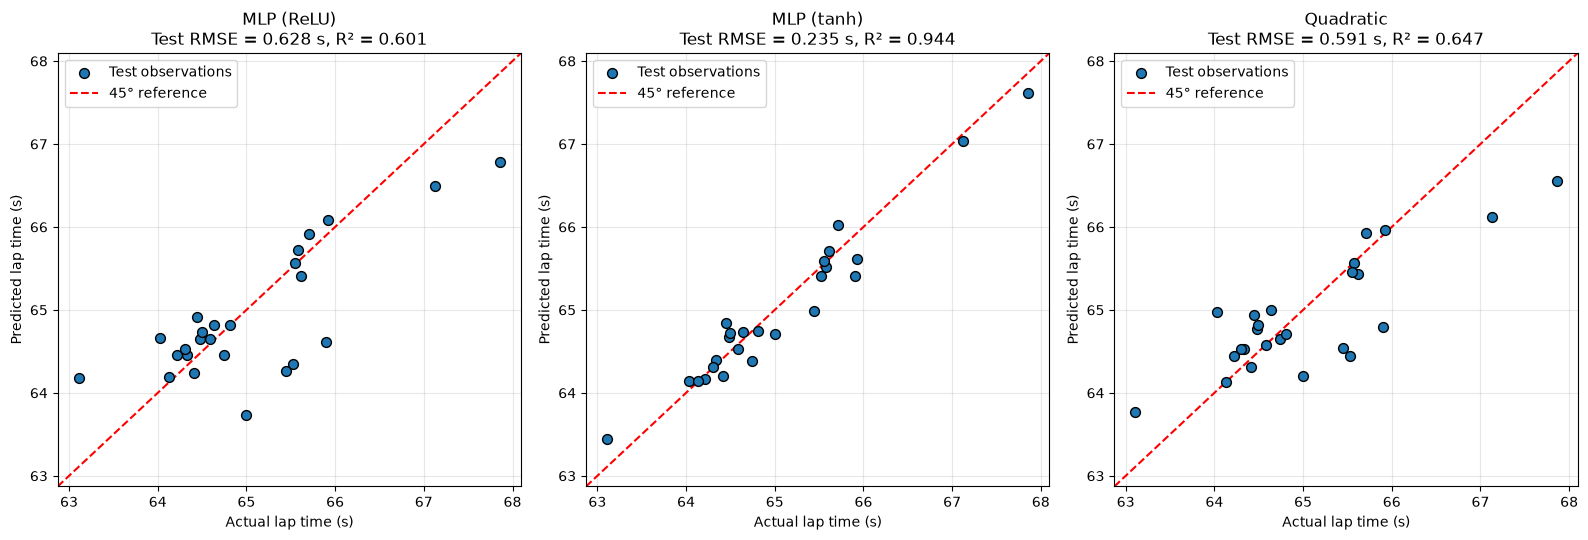

In [152]:
#29
# Predictions for all 100 observations, from models fitted on the 75 training rows only
X_lap_all_n = normalize_lap(df_lap[lap_inputs].to_numpy(dtype=float))
test_ids = set(df_lap_test["row_id"])

df_lap_pred = pd.DataFrame({
    "row_id": df_lap["row_id"],
    "split": ["test" if r in test_ids else "train" for r in df_lap["row_id"]],
    "fuel_kg": df_lap["fuel_kg"],
    "tire_age_laps": df_lap["tire_age_laps"],
    "actual_time_s": df_lap["time_s"],
    "relu_prediction_s": mlp_relu.predict(X_lap_all_n),
    "tanh_prediction_s": mlp_tanh.predict(X_lap_all_n),
    "quadratic_prediction_s": predict_quad(X_lap_all_n, b_lap_quad),
})
df_lap_pred.to_csv("wfrazer_pr03_laptime_predictions.csv", index=False)
print(df_lap_pred["split"].value_counts())

# Actual vs predicted, test observations only
names = ["MLP (ReLU)", "MLP (tanh)", "Quadratic"]
keys = ["relu", "tanh", "quad"]
all_vals = np.concatenate([y_lap_test] + [lap_test_pred[k] for k in keys])
pad = 0.05 * (all_vals.max() - all_vals.min())
lims = [all_vals.min() - pad, all_vals.max() + pad]

fig, ax = plt.subplots(1, 3, figsize=(16, 5.5))
for i in range(3):
    p = lap_test_pred[keys[i]]
    ax[i].scatter(y_lap_test, p, edgecolor="k", s=50, zorder=3, label="Test observations")
    ax[i].plot(lims, lims, "r--", label="45° reference")
    ax[i].set_xlim(lims)
    ax[i].set_ylim(lims)
    ax[i].set_xlabel("Actual lap time (s)")
    ax[i].set_ylabel("Predicted lap time (s)")
    ax[i].set_title(f"{names[i]}\nTest RMSE = {rmse(y_lap_test, p):.3f} s, R² = {r2(y_lap_test, p):.3f}")
    ax[i].grid(alpha=0.3)
    ax[i].legend(loc="upper left")
plt.tight_layout()
plt.savefig("wfrazer_pr03_laptime_validation.png", dpi=200)
plt.show()

In [153]:
#30
# Grid workflow adapted from Lec 16
x1_grid = np.linspace(df_lap["fuel_kg"].min(), df_lap["fuel_kg"].max(), 50)
x2_grid = np.linspace(df_lap["tire_age_laps"].min(), df_lap["tire_age_laps"].max(), 50)

X1, X2 = np.meshgrid(x1_grid, x2_grid)               
X_grid = np.column_stack([X1.ravel(), X2.ravel()])
X_grid_n = (X_grid - X_nn_min) / (X_nn_max - X_nn_min)
Y_relu = mlp_relu.predict(X_grid_n).reshape(X1.shape)
Y_tanh = mlp_tanh.predict(X_grid_n).reshape(X1.shape)
Y_quad = predict_quad(X_grid_n, b_lap_quad).reshape(X1.shape)

#31
Discussion: neural network lap-time models

Each hidden neuron computes a weighted sum of its inputs plus a bias, then applies an activation function.ReLU outputs max(0, x), which is piecewise linear, so a ReLU network builds the surface from flat facets joined at creases. 

tanh is a smooth S-shaped curve, so each tanh neuron changes gradually rather than bending sharply. 

In my plots,  the ReLU surface is a broad, fairly smooth saddle that looks more similar to the quadratic.

While the tanh surface is much more uneven, with local peaks and dips around individual training laps. 

So a smooth activation function did not produce the smoothest surface here; with the same fixed settings, the tanh network bent more closely to the training data.

The weights and biases  are learned by L-BFGS from the 75 training observations. The hyperparameters were fixed in advance and not tuned.

These results come from a single 75/25 split, so a different split or seed could change the ranking. 

Predictions are least reliable in sparsely sampled regions and near the edges of the fuel and tire-age ranges, where few training observations constrain the networks. 